# 08 Simulation Result

Ziel der Simulation ist ein Folgejahr (Jahr 2), in dem die empfohlenen Maßnahmen umgesetzt sind. Grundlage ist der reale Datensatz (Jahr 1): Aus ihm werden für jede Zelle die Unfallzahl und der Anteil schwerer Unfälle übernommen; Jahr 2 ergibt sich daraus mit zufälligen Schwankungen und der angenommenen Wirkung der Maßnahmen.

**Annahmen:**
- Maßnahme senkt schwere Unfälle in ihrer Zielsituation um 30 %.
- Szenario: HS2 (M1) und HS3 (M2) umgesetzt; HS1 nicht.
- Rückkehr zum Mittelwert (Regression to the Mean) wird modelliert.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from katalog import katalog, massnahmen_empfehlen

df_unfall = pd.read_parquet('../../data/df_unfall_gps.parquet')
df_clean  = pd.read_parquet('../../data/df_features_gps.parquet')
zellen    = pd.read_parquet('../../data/zellen.parquet')
hotspots  = pd.read_parquet('../../data/hotspots.parquet')
with open('../../data/kontrolle.json') as f:
    kontrolle = json.load(f)

bu, bf = df_unfall['schwer'].mean(), df_clean['schwer'].mean()
print('df_unfall:', len(df_unfall), '| zellen:', len(zellen), '| hotspots:', len(hotspots))

df_unfall: 9517 | zellen: 570 | hotspots: 3


In [31]:
# Annahmen der Simulation
WIRKUNG   = 0.30
K_SHRINK  = 40
UMGESETZT = {'HS1': False, 'HS2': True, 'HS3': True}
KOSTEN    = {'M1': 25000, 'M2': 40000, 'M3': 10000, 'M4': 35000, 'M5': 30000, 'M6': 15000, 'M7': 30000}

def geschrumpft(schwer, n, ziel):
    return (schwer + K_SHRINK * ziel) / (n + K_SHRINK)

zellen['p_wahr'] = geschrumpft(zellen['schwer'], zellen['n'], bu)
bed = {m['ID']: m['Bedingung'] for m in katalog}
for z, r in hotspots.iterrows():
    unf = df_unfall[df_unfall['Zelle'] == z]
    ziel_stadt = bed[r['Massnahme_ID']](df_unfall)
    ziel = bed[r['Massnahme_ID']](unf)
    hotspots.loc[z, 'anteil_ziel'] = ziel.mean()
    hotspots.loc[z, 'p_ziel'] = geschrumpft(unf.loc[ziel, 'schwer'].sum(), ziel.sum(),
                                            df_unfall.loc[ziel_stadt, 'schwer'].mean())
    hotspots.loc[z, 'p_rest'] = geschrumpft(unf.loc[~ziel, 'schwer'].sum(), (~ziel).sum(),
                                            df_unfall.loc[~ziel_stadt, 'schwer'].mean())
hotspots[['Hotspot', 'Massnahme_ID', 'anteil_ziel', 'p_ziel', 'p_rest']].round(3).assign(
    umgesetzt=hotspots['Hotspot'].map(UMGESETZT))

,Hotspot,Massnahme_ID,anteil_ziel,p_ziel,p_rest,umgesetzt
Zelle,,,,,,
1002_4307,HS1,M4,0.039,0.245,0.206,False
998_4309,HS2,M1,0.172,0.292,0.180,True
1003_4320,HS3,M2,0.240,0.227,0.201,True


In [32]:
def simuliere_jahr2(rng, umgesetzt):
    n2 = rng.poisson(zellen['n'].values)
    s2 = rng.binomial(n2, zellen['p_wahr'].values)
    for z, r in hotspots.iterrows():
        i = zellen.index.get_loc(z)
        n_ziel = rng.binomial(n2[i], r['anteil_ziel'])
        p_ziel = r['p_ziel'] * (1 - WIRKUNG) if umgesetzt[r['Hotspot']] else r['p_ziel']
        s2[i] = rng.binomial(n_ziel, p_ziel) + rng.binomial(n2[i] - n_ziel, r['p_rest'])
    return pd.DataFrame({'n2': n2, 'schwer2': s2}, index=zellen.index)

Ein einzelnes simuliertes Jahr schwankt stark (Zufall). Die Wirkung wird deshalb mit **1.000 Simulationen** je Szenario geschätzt (Monte-Carlo).

,Hotspot,umgesetzt,schwer_J1,J2_ohne,J2_mit,Rueckgang_ohne_Massnahme (RTM),vermeiden_durch_Massnahme,DiD_vs_Kontrolle
0,HS1,False,30,26.8,26.8,3.2,0.0,-3.5
1,HS2,True,28,24.0,22.2,4.0,1.8,-5.8
2,HS3,True,19,15.5,14.3,3.5,1.2,-5.2


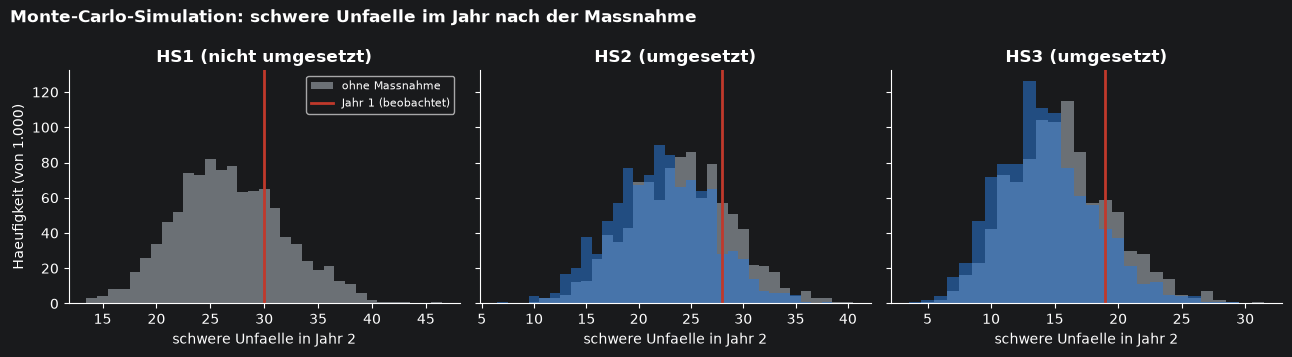

In [33]:
N_SIM = 1000
ohne_massnahme = {h: False for h in UMGESETZT}
mc = {h: {'mit': [], 'ohne': [], 'did': []} for h in hotspots['Hotspot']}
for i in range(N_SIM):
    j_mit = simuliere_jahr2(np.random.default_rng(1000 + i), UMGESETZT)
    j_ohne = simuliere_jahr2(np.random.default_rng(1000 + i), ohne_massnahme)
    for z, r in hotspots.iterrows():
        h, ks = r['Hotspot'], kontrolle[r['Hotspot']]
        mc[h]['mit'].append(j_mit.loc[z, 'schwer2'])
        mc[h]['ohne'].append(j_ohne.loc[z, 'schwer2'])
        d_k = (j_mit.loc[ks, 'schwer2'] - zellen.loc[ks, 'schwer']).mean()
        mc[h]['did'].append((j_mit.loc[z, 'schwer2'] - r['schwer']) - d_k)

rows = []
for z, r in hotspots.iterrows():
    h = r['Hotspot']
    v = {k: np.array(x) for k, x in mc[h].items()}
    rows.append({'Hotspot': h, 'umgesetzt': UMGESETZT[h], 'schwer_J1': int(r['schwer']),
                 'J2_ohne': v['ohne'].mean(), 'J2_mit': v['mit'].mean(),
                 'Rueckgang_ohne_Massnahme (RTM)': r['schwer'] - v['ohne'].mean(),
                 'vermeiden_durch_Massnahme': v['ohne'].mean() - v['mit'].mean(),
                 'DiD_vs_Kontrolle': v['did'].mean()})
mc_tab = pd.DataFrame(rows).round(1)
display(mc_tab)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (h, v) in zip(axs, mc.items()):
    j1_val = hotspots.set_index('Hotspot').loc[h, 'schwer']
    alle = v['mit'] + v['ohne']
    bins = np.arange(min(alle) - 0.5, max(alle) + 1.5)
    ax.hist(v['ohne'], bins=bins, alpha=0.55, color='#b0b7bf', label='ohne Massnahme')
    if UMGESETZT[h]:
        ax.hist(v['mit'], bins=bins, alpha=0.55, color='#2a78d6', label='mit Massnahme')
    ax.axvline(j1_val, color='#c0392b', lw=2, label='Jahr 1 (beobachtet)')
    ax.set_title(f'{h} ({"umgesetzt" if UMGESETZT[h] else "nicht umgesetzt"})', fontweight='bold')
    ax.set_xlabel('schwere Unfaelle in Jahr 2')
    ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('Haeufigkeit (von 1.000)')
axs[0].legend(fontsize=8)
fig.suptitle('Monte-Carlo-Simulation: schwere Unfaelle im Jahr nach der Massnahme', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

**Ergebnis:** Die echte Wirkung ist die Differenz *mit − ohne* Maßnahme. Ohne Maßnahme sinken Hotspots bereits durch Regression to the Mean.

Für den Prototyp werden die Ergebnisse in einzelne Unfallmeldungen überführt: Jahr 1 enthält die realen Unfälle, für Jahr 2 werden je Zelle so viele Unfälle erzeugt, wie die Simulation vorgibt. Jeder Unfall erhält ein zufälliges Datum. Dieser Datenfeed wird anschließend per MQTT an ThingsBoard gesendet und simuliert eingehende Polizeimeldungen.

In [34]:
erwartet = zellen['n'] * zellen['p_wahr']
for z, r in hotspots.iterrows():
    p_z = r['p_ziel'] * (1 - WIRKUNG) if UMGESETZT[r['Hotspot']] else r['p_ziel']
    erwartet[z] = r['n'] * (r['anteil_ziel'] * p_z + (1 - r['anteil_ziel']) * r['p_rest'])
relevant = list(hotspots.index) + sum(kontrolle.values(), [])
abstand = lambda j: ((j.loc[relevant, 'schwer2'] - erwartet[relevant]) ** 2).sum()
seed = min(range(200), key=lambda sd: abstand(simuliere_jahr2(np.random.default_rng(sd), UMGESETZT)))
jahr2 = simuliere_jahr2(np.random.default_rng(seed), UMGESETZT)

# Zufälliges Datum je Unfall (Datensatz enthält keine Datumsangaben)
def zufallsdatum(jahr, anzahl, rng):
    tage = rng.integers(0, 365, size=anzahl)
    return pd.Timestamp(f"{jahr}-01-01") + pd.to_timedelta(tage, unit="D")

rng_d = np.random.default_rng(1)

# Jahr 1: reale Unfälle
j1 = df_unfall.copy()
j1["Jahr"] = 2025
j1["Zeitpunkt"] = zufallsdatum(2025, len(j1), rng_d) + pd.to_timedelta(j1["Time"].astype(str), errors="coerce")

# Jahr 2: je Zelle n2 Unfälle (Merkmale aus Jahr 1 gezogen), Schwere aus der Simulation
rng_j2 = np.random.default_rng(7)
teile = []
for z, grp in j1.groupby("Zelle"):
    n2, s2 = jahr2.loc[z, "n2"], jahr2.loc[z, "schwer2"]
    if n2 == 0:
        continue
    neu = grp.sample(n2, replace=True, random_state=int(rng_j2.integers(1e9))).copy()
    schwer_neu = np.zeros(n2, dtype=int)
    schwer_neu[rng_j2.choice(n2, min(s2, n2), replace=False)] = 1
    neu["schwer"] = schwer_neu
    neu["Accident_severity"] = np.where(schwer_neu == 1, "Serious Injury", "Slight Injury")
    teile.append(neu)
j2 = pd.concat(teile)
j2["Jahr"] = 2026
j2["Zeitpunkt"] = zufallsdatum(2026, len(j2), rng_d) + pd.to_timedelta(j2["Time"].astype(str), errors="coerce")

feed = pd.concat([j1, j2], ignore_index=True)

# Gruppe je Unfall: Hotspot / Kontrollzelle / Sonstige
gruppe = pd.Series("Sonstige", index=zellen.index)
for z, r in hotspots.iterrows():
    gruppe[z] = r["Hotspot"]
    gruppe[kontrolle[r["Hotspot"]]] = "Kontrolle_" + r["Hotspot"]
feed["Gruppe"] = feed["Zelle"].map(gruppe)

hs_umg = [h for h, u in UMGESETZT.items() if u]     # wird beim Export benötigt
print(f"Datenfeed: {len(feed)} Unfälle ({len(j1)} Jahr 1, {len(j2)} Jahr 2)")

Datenfeed: 18995 Unfälle (9517 Jahr 1, 9478 Jahr 2)


In [35]:
mc_tab.to_parquet('../../data/mc_tab.parquet', index=False)
feed.to_parquet('../../src/daten/feed.parquet', index=False)
print('Gespeichert: mc_tab.parquet', mc_tab.shape)
print('Gespeichert: feed.parquet', feed.shape)

Gespeichert: mc_tab.parquet (3, 8)
Gespeichert: feed.parquet (18995, 48)
